In [1]:
import h5py
import halotools
import os
import copy
import warnings
import numpy as np
import math
from astropy.modeling import Fittable1DModel, Parameter,models,fitting
import pickle
import warnings
import numpy.ma as ma
import pandas as pd
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit
from scipy.stats import spearmanr,kendalltau,pearsonr,ks_2samp
import palettable
import deepdish as dd
import matplotlib.cm as cm
import pingouin as pg

from matplotlib.collections import LineCollection
from photutils.isophote import EllipseGeometry
from photutils.aperture import EllipticalAperture,EllipticalAnnulus
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import rcParams
from matplotlib import colors
from astroML.stats import binned_statistic_2d
from scipy.ndimage import gaussian_filter
from sklearn.linear_model import LinearRegression

from astropy.utils.console import ProgressBar
from astropy.table import QTable,hstack
plt.rc('text', usetex=True)
rcParams.update({'axes.linewidth': 1.5})
rcParams.update({'xtick.direction': 'in'})
rcParams.update({'ytick.direction': 'in'})
rcParams.update({'xtick.minor.visible': 'True'})
rcParams.update({'ytick.minor.visible': 'True'})
rcParams.update({'xtick.major.pad': '7.0'})
rcParams.update({'xtick.major.size': '8.0'})
rcParams.update({'xtick.major.width': '1.5'})
rcParams.update({'xtick.minor.pad': '7.0'})
rcParams.update({'xtick.minor.size': '4.0'})
rcParams.update({'xtick.minor.width': '1.5'})
rcParams.update({'ytick.major.pad': '7.0'})
rcParams.update({'ytick.major.size': '8.0'})
rcParams.update({'ytick.major.width': '1.5'})
rcParams.update({'ytick.minor.pad': '7.0'})
rcParams.update({'ytick.minor.size': '4.0'})
rcParams.update({'ytick.minor.width': '1.5'})
rcParams.update({'axes.titlepad': '10.0'})
rcParams.update({'font.size': 35})

/Users/xushuo/miniconda3/envs/tardis/lib/python3.8/site-packages/outdated/utils.py:14: OutdatedPackageWarning: The package pingouin is out of date. Your version is 0.5.1, the latest is 0.7.0.
Set the environment variable OUTDATED_IGNORE=1 to disable these warnings.
  return warn(


In [2]:
fig_dir="/Users/xushuo/work/Papers/HistoricRichness/Figure/"

In [4]:
file_dir='/Users/xushuo/work/Submit/HistoricRichness/Data/'
from astropy.table import Table

peak_table = Table.read(
    '/Users/xushuo/work/Submit/HistoricRichness/Data/fossil_peak_age_table.ecsv',
    format='ascii.ecsv',
)

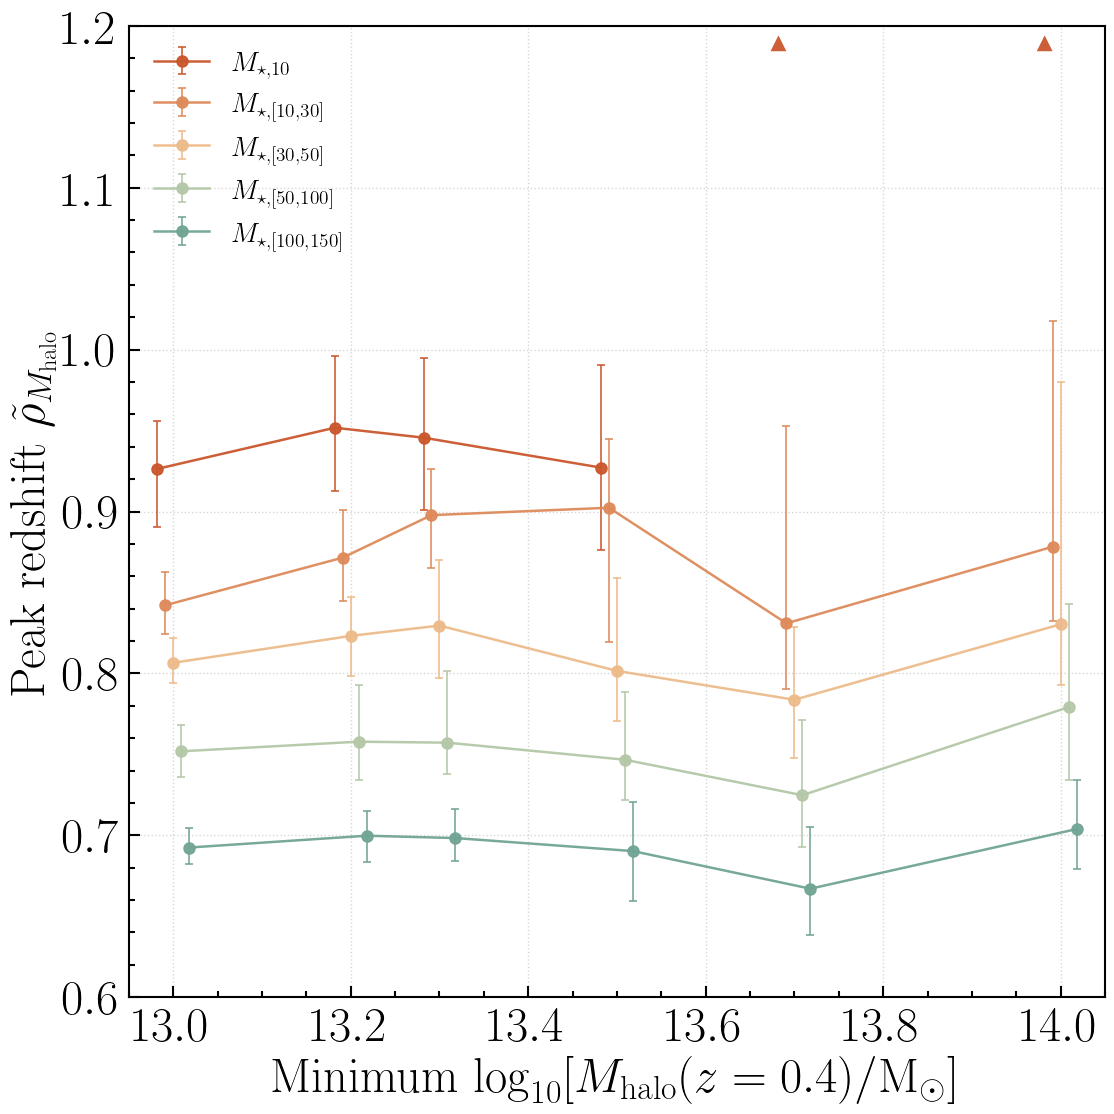

In [8]:
import numpy as np
import matplotlib.pyplot as plt

regions = [
    ('10',      r'$M_{\star,10}$'),
    ('10_30',   r'$M_{\star,[10,30]}$'),
    ('30_50',   r'$M_{\star,[30,50]}$'),
    ('50_100',  r'$M_{\star,[50,100]}$'),
    ('100_150', r'$M_{\star,[100,150]}$'),
]

# 保留你当前的颜色设置
colors = palettable.cartocolors.diverging.Geyser_6.mpl_colors[::-1]

x = np.asarray(peak_table['logM_min'], dtype=float)

z_min, z_max = 0.6, 1.2

# 每个 region 使用不同的横向偏移，避免 errorbar 重叠
# 总偏移范围很小，不会改变 mass threshold 的含义
x_offsets = np.linspace(-0.018, 0.018, len(regions))

# 三角略低于上边界，保证整个 marker 都能显示
triangle_y = z_max - 0.018 * (z_max - z_min)

fig, ax = plt.subplots(figsize=(12, 12))

for i, ((tag, label), color) in enumerate(zip(regions, colors)):
    z_peak = np.asarray(
        peak_table['z_peak_' + tag], dtype=float
    )

    # 当前 region 的所有点使用相同的横向偏移
    x_plot = x + x_offsets[i]

    if 'z_peak_' + tag + '_low' in peak_table.colnames:
        z_low = np.asarray(
            peak_table['z_peak_' + tag + '_low'], dtype=float
        )
        z_upp = np.asarray(
            peak_table['z_peak_' + tag + '_upp'], dtype=float
        )

        err_lo = np.maximum(z_peak - z_low, 0.0)
        err_hi = np.maximum(z_upp - z_peak, 0.0)
        yerr = np.vstack([err_lo, err_hi])
    else:
        yerr = np.asarray(
            peak_table['z_peak_' + tag + '_err'], dtype=float
        )

    # 中心峰位在图内：正常画点和 errorbar
    inside = np.isfinite(z_peak) & (z_peak <= z_max)

    # 中心峰位高于图上界：改画上三角，不画 errorbar
    above = np.isfinite(z_peak) & (z_peak > z_max)

    ax.errorbar(
        x_plot[inside],
        z_peak[inside],
        yerr=yerr[:, inside] if np.ndim(yerr) == 2 else yerr[inside],
        fmt='o',
        linestyle='-',
        color=color,
        markersize=8,
        linewidth=1.8,
        elinewidth=1.2,
        capsize=3,
        capthick=1.2,
        alpha=0.95,
        label=label,
    )

    if np.any(above):
        ax.scatter(
            x_plot[above],
            np.full(np.sum(above), triangle_y),
            marker='^',
            s=130,
            color=color,
            alpha=0.95,
            edgecolors='none',
            zorder=5,
        )

ax.set_xlabel(
    r'\rm Minimum  '
    r'$\log_{10}[M_{\mathrm{halo}}(z=0.4)/\mathrm{M}_{\odot}]$',
)
ax.set_ylabel(
    r'\rm Peak redshift $\tilde{\rho}_{M_{\rm halo}}$',
)

ax.grid(linestyle=':', linewidth=1.0, alpha=0.5)
ax.set_axisbelow(True)

ax.set_ylim(z_min, z_max)
ax.set_xlim(x.min() - 0.05, x.max() + 0.05)

ax.legend(
    fontsize=20,
    title_fontsize=10.5,
    frameon=False,
    loc='best',
)

fig.tight_layout()

# fig.savefig('peak_redshift_vs_mass_threshold.pdf',
#             bbox_inches='tight')
# fig.savefig('peak_redshift_vs_mass_threshold.png',
#             dpi=300, bbox_inches='tight')

fig.savefig(
    fig_dir + 'FigA2.pdf',
    bbox_inches='tight',
)